# Phân loại bệnh lá lúa bằng Machine Learning

1. Cân bằng ánh sáng bằng **CLAHE**.
2. Trích đặc trưng màu **HSV** và đặc trưng hình dạng **HOG**.
3. Tăng cường dữ liệu nhẹ cho tập train.
4. So sánh 6 thuật toán Machine Learning bằng **Macro F1**.
5. Chọn mô hình tốt nhất và tạo `submission.csv`.



## 1. Thư viện và cấu hình

In [1]:
import json, random
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
from tqdm.auto import tqdm
from skimage.feature import hog

from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.metrics import f1_score, classification_report, ConfusionMatrixDisplay
from sklearn.utils.class_weight import compute_sample_weight

SEED = 42
IMAGE_SIZE = (128, 128)
VAL_RATIO = 0.15
TEST_FOLDER = "test_warmup"       # đổi thành tên thư mục test khác khi cần
USE_AUGMENTATION = True
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

random.seed(SEED)
np.random.seed(SEED)

## 2. Đọc dữ liệu

In [2]:
def find_dataset_root(input_dir=Path("/kaggle/input")):
    for mapping_file in input_dir.rglob("label_mapping.json"):
        root = mapping_file.parent
        if (root / "train").is_dir() and (root / TEST_FOLDER).is_dir():
            return root
    raise FileNotFoundError("Chưa tìm thấy train, thư mục test và label_mapping.json")

BASE_DIR = find_dataset_root()
TRAIN_DIR = BASE_DIR / "train"
TEST_DIR = BASE_DIR / TEST_FOLDER

with open(BASE_DIR / "label_mapping.json", encoding="utf-8") as f:
    label_mapping = json.load(f)

class_names = [name for name, label in sorted(label_mapping.items(), key=lambda x: int(x[1]))]
idx_to_class = {int(label): name for name, label in label_mapping.items()}

image_paths, image_labels = [], []
for class_name in class_names:
    files = sorted(p for p in (TRAIN_DIR / class_name).iterdir()
                   if p.suffix.lower() in IMAGE_EXTENSIONS)
    image_paths.extend(files)
    image_labels.extend([int(label_mapping[class_name])] * len(files))

print("Dữ liệu:", BASE_DIR)
print("Số ảnh train:", len(image_paths))
print(pd.Series(image_labels).map(idx_to_class).value_counts())

Dữ liệu: /kaggle/input/competitions/fptu-can-tho-olympic-ai-2026-vong-lo-i-warmup
Số ảnh train: 2026
Leaf Blast                360
Sheath Blight             352
Brown Spot                289
Rice Hispa                260
Bacterial Leaf Blight     226
Leaf scald                220
Healthy Rice Leaf         193
Narrow Brown Leaf Spot    126
Name: count, dtype: int64


## 3. CLAHE, HSV và HOG

In [3]:
def normalize_light(image):
    lab = cv2.cvtColor(image, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    l = cv2.createCLAHE(2.0, (8, 8)).apply(l)
    return cv2.cvtColor(cv2.merge((l, a, b)), cv2.COLOR_LAB2BGR)


def extract_features(image):
    image = cv2.resize(image, IMAGE_SIZE, interpolation=cv2.INTER_AREA)
    image = normalize_light(image)
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    features = []
    for channel, bins, value_range in [(0, 18, [0, 180]), (1, 16, [0, 256]), (2, 16, [0, 256])]:
        hist = cv2.calcHist([hsv], [channel], None, [bins], value_range)
        features.extend(cv2.normalize(hist, hist).ravel())
        features.extend([hsv[:, :, channel].mean(), hsv[:, :, channel].std()])

    features.extend(hog(gray, orientations=9, pixels_per_cell=(32, 32),
                        cells_per_block=(1, 1), block_norm="L2-Hys"))
    return np.asarray(features, dtype=np.float32)

sample = cv2.imread(str(image_paths[0]))
print("Số chiều đặc trưng:", len(extract_features(sample)))

Số chiều đặc trưng: 200


## 4. Tăng cường dữ liệu và tạo ma trận đặc trưng

In [4]:
def augment(image):
    if not USE_AUGMENTATION:
        return [image]

    h, w = image.shape[:2]
    center = (w // 2, h // 2)
    versions = [image, cv2.flip(image, 1),
                cv2.convertScaleAbs(image, beta=30),
                cv2.convertScaleAbs(image, beta=-30),
                cv2.GaussianBlur(image, (5, 5), 0)]

    for angle in (-10, 10):
        matrix = cv2.getRotationMatrix2D(center, angle, 1.0)
        versions.append(cv2.warpAffine(image, matrix, (w, h), borderMode=cv2.BORDER_REFLECT))
    return versions


def build_features(paths, labels=None, use_augmentation=False):
    X, y = [], []
    for i, path in enumerate(tqdm(paths)):
        image = cv2.imread(str(path))
        if image is None:
            raise ValueError(f"Không đọc được ảnh: {path}")
        versions = augment(image) if use_augmentation else [image]
        X.extend(extract_features(version) for version in versions)
        if labels is not None:
            y.extend([labels[i]] * len(versions))
    X = np.asarray(X, dtype=np.float32)
    return (X, np.asarray(y)) if labels is not None else X

In [5]:
train_paths, val_paths, train_labels, val_labels = train_test_split(
    image_paths, image_labels, test_size=VAL_RATIO,
    stratify=image_labels, random_state=SEED
)

X_train, y_train = build_features(train_paths, train_labels, True)
X_val, y_val = build_features(val_paths, val_labels)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

print("Train:", X_train_scaled.shape)
print("Validation:", X_val_scaled.shape)

  0%|          | 0/1722 [00:00<?, ?it/s]

  0%|          | 0/304 [00:00<?, ?it/s]

Train: (12054, 200)
Validation: (304, 200)


## 5. So sánh các thuật toán

In [6]:
models = {
    "Decision Tree": DecisionTreeClassifier(max_depth=15, class_weight="balanced", random_state=SEED),
    "KNN": KNeighborsClassifier(n_neighbors=7),
    "SVM": SVC(C=10, kernel="rbf", class_weight="balanced", random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=SEED, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=200, max_depth=3, random_state=SEED),
    "AdaBoost": AdaBoostClassifier(n_estimators=200, learning_rate=1.0, random_state=SEED),
}

weighted_models = {"Gradient Boosting", "AdaBoost"}
sample_weight = compute_sample_weight("balanced", y_train)
results = []

for name, model in models.items():
    fit_args = {"sample_weight": sample_weight} if name in weighted_models else {}
    model.fit(X_train_scaled, y_train, **fit_args)
    score = f1_score(y_val, model.predict(X_val_scaled), average="macro")
    results.append((name, score))

results = pd.DataFrame(results, columns=["Model", "Macro F1"]).sort_values("Macro F1", ascending=False)
display(results)

best_name = results.iloc[0]["Model"]
best_model = models[best_name]
print("Mô hình tốt nhất:", best_name)

,Model,Macro F1
3,Random Forest,0.946916
2,SVM,0.933352
4,Gradient Boosting,0.904359
1,KNN,0.841877
0,Decision Tree,0.824091
5,AdaBoost,0.485616


Mô hình tốt nhất: Random Forest


## 6. Đánh giá mô hình tốt nhất

                        precision    recall  f1-score   support

 Bacterial Leaf Blight      0.944     1.000     0.971        34
            Brown Spot      0.977     0.977     0.977        43
     Healthy Rice Leaf      0.893     0.862     0.877        29
            Leaf Blast      0.981     0.981     0.981        54
            Leaf scald      0.941     0.970     0.955        33
Narrow Brown Leaf Spot      1.000     0.842     0.914        19
            Rice Hispa      0.925     0.949     0.937        39
         Sheath Blight      0.962     0.962     0.962        53

              accuracy                          0.954       304
             macro avg      0.953     0.943     0.947       304
          weighted avg      0.954     0.954     0.954       304



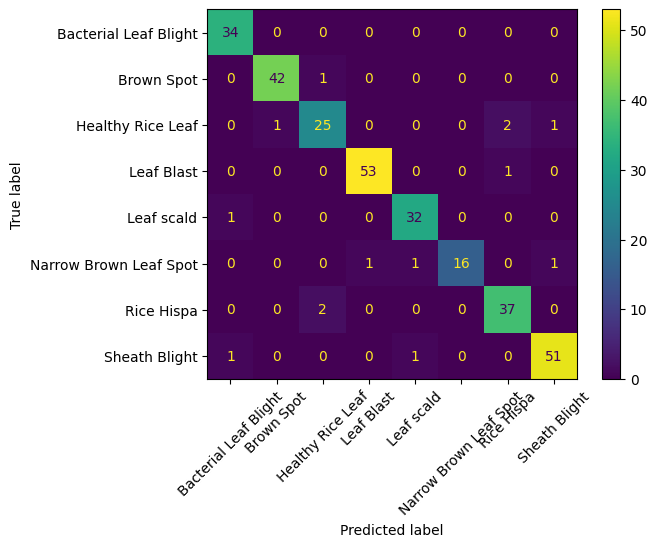

In [7]:
val_pred = best_model.predict(X_val_scaled)
print(classification_report(y_val, val_pred, labels=range(len(class_names)),
                            target_names=class_names, digits=3, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_val, val_pred, display_labels=class_names,
                                        xticks_rotation=45)

## 7. Huấn luyện toàn bộ dữ liệu và tạo submission

In [8]:
X_full, y_full = build_features(image_paths, image_labels, True)
final_scaler = StandardScaler()
X_full_scaled = final_scaler.fit_transform(X_full)

final_model = clone(models[best_name])
fit_args = {"sample_weight": compute_sample_weight("balanced", y_full)} if best_name in weighted_models else {}
final_model.fit(X_full_scaled, y_full, **fit_args)

test_paths = sorted(p for p in TEST_DIR.iterdir() if p.suffix.lower() in IMAGE_EXTENSIONS)
X_test = final_scaler.transform(build_features(test_paths))
final_pred = final_model.predict(X_test).astype(int)

submission = pd.DataFrame({
    "image_id": [p.name for p in test_paths],
    "label": final_pred
})

OUTPUT_PATH = "/kaggle/working/submission.csv"
submission.to_csv(OUTPUT_PATH, index=False)
print("Đã lưu:", OUTPUT_PATH)
display(submission.head())

  0%|          | 0/2026 [00:00<?, ?it/s]

  0%|          | 0/300 [00:00<?, ?it/s]

Đã lưu: /kaggle/working/submission.csv


,image_id,label
0,public_0001.jpg,6
1,public_0002.jpg,7
2,public_0003.jpg,3
3,public_0004.jpg,2
4,public_0005.jpg,4


## Ghi chú trình bày

- **CLAHE** giảm ảnh hưởng của ánh sáng không đồng đều.
- **HSV** mô tả màu sắc của vùng bệnh.
- **HOG** mô tả cạnh và hình dạng vết bệnh.
- **StandardScaler** giúp các đặc trưng có cùng thang đo.
- **Macro F1** đánh giá công bằng hơn khi số ảnh giữa các lớp không bằng nhau.